# LP ETH/USDT 0.3% — Uniswap V3 | Полный анализ
**Пул:** `0x4e68Ccd3E89f51C3074ca5072bbAC773960dFa36`  
**Период:** 2025-03-31 → 2026-03-30 | **Инвестиция:** $20 000

---
### Структура:
0. Библиотеки и вспомогательные функции  
1. Загрузка и подготовка данных  
2. Описательная статистика  
3. VIF — мультиколлинеарность  
4. OLS+HC3 — Модели A (fee_APY), B (IL_pct), C (log LP return) + Huber  
5. Анализ временного ряда IL_pct: ACF · PACF · ADF · Ljung-Box · JB · ARCH-LM · ARMA · GARCH  
6. Меры риска: VaR · CVaR · Sharpe · Sortino · Calmar · Max Drawdown · Greeks  
7. Графики  
8. Финальная сводка

## 0. Библиотеки и вспомогательные функции

In [8]:
import subprocess
subprocess.run(["pip", "install", "openpyxl", "arch", "statsmodels", "-q"], capture_output=True)

import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings("ignore")
from sklearn.linear_model import HuberRegressor
from sklearn.preprocessing import StandardScaler
from arch import arch_model

DARK, PANEL = "#0F1117", "#1A1D27"
GREEN, BLUE, RED = "#2ECC71", "#3498DB", "#E74C3C"
GOLD, GRAY, WHITE = "#F1C40F", "#7F8C8D", "#ECF0F1"
SEP = "=" * 70

def sig(p):
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.1 else ""))

def ax_style(ax, title):
    ax.set_facecolor(PANEL)
    for sp in ax.spines.values(): sp.set_edgecolor("#2C3E50")
    ax.tick_params(colors=GRAY, labelsize=8)
    ax.set_title(title, color=WHITE, fontsize=9, fontweight="bold", pad=6)
    ax.xaxis.label.set_color(GRAY); ax.yaxis.label.set_color(GRAY)

def ols_hc3(X, y, names):
    n, kf = X.shape; k = kf - 1
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    yh = X @ b; e = y - yh
    ssr = np.sum(e**2); sst = np.sum((y - y.mean())**2)
    r2 = 1 - ssr/sst; r2a = 1 - (1-r2)*(n-1)/(n-k-1)
    Xi = np.linalg.pinv(X.T @ X)
    h = np.einsum("ij,jk,ik->i", X, Xi, X)
    ea = e / np.maximum(1-h, 0.01)
    V = Xi @ ((X*ea[:,None]).T @ (X*ea[:,None])) @ Xi
    se = np.sqrt(np.clip(np.diag(V), 0, None))
    tv = b / np.where(se>0, se, 1e-10)
    pv = 2*st.t.sf(np.abs(tv), df=n-k-1)
    fs = ((sst-ssr)/k)/(ssr/(n-k-1)); fp = st.f.sf(fs, k, n-k-1)
    dw = np.sum(np.diff(e)**2)/ssr
    jbs, jbp = st.jarque_bera(e)
    return dict(n=n, k=k, r2=r2, r2adj=r2a, f=fs, fp=fp, dw=dw,
                beta=b, se=se, t=tv, p=pv, yhat=yh, resid=e,
                jb=jbs, jbp=jbp, skew=st.skew(e), kurt=st.kurtosis(e), cols=names)

def bX(d, cols):
    return np.column_stack([np.ones(len(d))] + [d[c].values for c in cols])

def run_ols(Xc, yc, data=None, standardize=False):
    if data is None: data = df_m
    use = [c for c in Xc if c in data.columns]
    s = data[use+[yc]].dropna().replace([np.inf,-np.inf], np.nan).dropna()
    if len(s) < max(len(use)+5, 20): return None, None
    if standardize:
        scaler = StandardScaler()
        X_raw = bX(s, use)
        X_scaled = np.column_stack([X_raw[:,0], scaler.fit_transform(X_raw[:,1:])])
        return ols_hc3(X_scaled, s[yc].values, ["const"]+use), s
    return ols_hc3(bX(s, use), s[yc].values, ["const"]+use), s

def print_ols(label, r):
    if r is None: print(f"  {label}: нет данных"); return
    print(f"\n  {chr(9472)*65}")
    print(f"  {label}")
    print(f"  N={r['n']}  R\u00b2={r['r2']:.4f}  R\u00b2adj={r['r2adj']:.4f}  F={r['f']:.2f} (p={r['fp']:.2e})  DW={r['dw']:.2f}")
    print(f"  JB={r['jb']:.1f} (p={r['jbp']:.4f})  Skew={r['skew']:.3f}  Kurt={r['kurt']:.2f}")
    print(f"  {chr(9472)*65}")
    print(f"  {'Переменная':<28} {'β':>10} {'SE_HC3':>9} {'t':>7} {'p':>9}  Знач.")
    print(f"  {chr(9472)*65}")
    for i, nm in enumerate(r["cols"]):
        print(f"  {nm[:28]:<28} {r['beta'][i]:>10.5f} {r['se'][i]:>9.5f} {r['t'][i]:>7.3f} {r['p'][i]:>9.4f}  {sig(r['p'][i])}")

def huber_ols(Xc, yc, data=None):
    if data is None: data = df_m
    use = [c for c in Xc if c in data.columns]
    s = data[use+[yc]].dropna().replace([np.inf,-np.inf], np.nan).dropna()
    if len(s) < 30: return None
    X_raw = s[use].values; y_raw = s[yc].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_raw)
    hub = HuberRegressor(epsilon=1.35, max_iter=500, alpha=0)
    hub.fit(X_scaled, y_raw)
    coef_orig = hub.coef_ / scaler.scale_
    intercept_orig = hub.intercept_ - np.sum(coef_orig * scaler.mean_)
    beta = np.concatenate([[intercept_orig], coef_orig])
    Xb = bX(s, use); e = y_raw - Xb @ beta
    n_out = int(np.sum(hub.outliers_))
    n, k = len(y_raw), len(use)
    r2 = 1 - np.sum(e**2)/np.sum((y_raw-y_raw.mean())**2)
    r2adj = 1 - (1-r2)*(n-1)/(n-k-1)
    mse = np.sum(e[~hub.outliers_]**2)/max(np.sum(~hub.outliers_)-k-1, 1)
    se = np.sqrt(np.diag(mse * np.linalg.pinv(Xb.T @ Xb)))
    tv = beta / se; pv = 2*st.t.sf(np.abs(tv), df=n-k-1)
    return dict(n=n, n_out=n_out, r2=r2, r2adj=r2adj, beta=beta, se=se, t=tv, p=pv, cols=["const"]+use)

def calc_vif(data, cols):
    X = data[cols].dropna().values; vifs = []
    for i in range(len(cols)):
        yv = X[:,i]; Xv = np.column_stack([np.ones(len(yv)), np.delete(X,i,axis=1)])
        b, _, _, _ = np.linalg.lstsq(Xv, yv, rcond=None); yh = Xv@b
        r2 = 1 - np.sum((yv-yh)**2)/np.sum((yv-yv.mean())**2)
        vifs.append(1/(1-r2) if r2<1 else np.inf)
    return pd.DataFrame({"Переменная":cols, "VIF":vifs})

def acf_fn(x, nl=30):
    x = np.asarray(x,float) - x.mean(); nx = len(x); v = np.var(x)
    if v==0: return [0.]*(nl+1)
    nl = min(nl, nx-1)
    return [1.]+[float(np.sum(x[:nx-k]*x[k:])/(nx*v)) for k in range(1,nl+1)]

def pacf_fn(x, nl=30):
    acv = acf_fn(x, nl); res = [1.]
    for k in range(1, nl+1):
        r = np.array(acv[1:k+1])
        if k==1: res.append(float(r[0])); continue
        R = np.array([[acv[abs(i-j)] for j in range(k-1)] for i in range(k-1)])
        try:
            phi = np.linalg.solve(R, r[:k-1]); den = 1 - np.dot(phi, r[:k-1])
            res.append(float((r[k-1]-np.dot(phi,r[:k-1][::-1]))/(den if abs(den)>1e-12 else 1e-12)))
        except: res.append(0.)
    return res

def ljung_box(x, lags=15):
    n = len(x); acv = acf_fn(x, lags)
    return [{"lag":h,
             "Q": round(n*(n+2)*sum(acv[k]**2/(n-k) for k in range(1,h+1)), 4),
             "p": round(float(1-st.chi2.cdf(n*(n+2)*sum(acv[k]**2/(n-k) for k in range(1,h+1)), df=h)), 4)}
            for h in range(1, lags+1)]

def ar_resid(x, p):
    xc = x-x.mean(); n = len(xc)
    if p==0: return xc
    Y = xc[p:]; X_ = np.column_stack([xc[p-i-1:n-i-1] for i in range(p)])
    b,_,_,_ = np.linalg.lstsq(X_, Y, rcond=None); return Y-X_@b

def arch_lm(x, ml=10):
    e2 = (x-x.mean())**2; n = len(e2); out = []
    for p in range(1, ml+1):
        T = n-p; Y = e2[p:]
        X_ = np.column_stack([np.ones(T)]+[e2[p-i-1:n-i-1] for i in range(p)])
        b,_,_,_ = np.linalg.lstsq(X_, Y, rcond=None); yh = X_@b
        r2 = 1-np.sum((Y-yh)**2)/max(np.sum((Y-Y.mean())**2), 1e-15)
        lm = T*r2
        out.append({"lag":p, "LM":round(lm,4), "p":round(float(1-st.chi2.cdf(lm, df=p)), 4)})
    return out

def adf_test(x, ml=12):
    x = np.asarray(x,float); dx = np.diff(x); n = len(x); ba, best = np.inf, {}
    for p in range(0, ml+1):
        T = len(dx)-p
        if T < max(20, p+5): continue
        Y = dx[p:]; X_ = np.column_stack([np.ones(T), x[p:n-1]]+[dx[p-i:n-1-i] for i in range(1,p+1)])
        try:
            b,_,_,_ = np.linalg.lstsq(X_, Y, rcond=None); e = Y-X_@b
            s2 = max(np.sum(e**2)/T, 1e-15); ll = -T/2*(np.log(2*np.pi*s2)+1)
            a = -2*ll + 2*X_.shape[1]
            if a < ba:
                ba = a; se_b = np.sqrt(max(s2*np.linalg.pinv(X_.T@X_)[1,1], 1e-20))
                best = {"stat": float(b[1]/se_b), "lag": p}
        except: continue
    if not best: return {"stat":np.nan, "p":np.nan, "lag":0, "cv":{"1%":-3.45,"5%":-2.87,"10%":-2.57}}
    tau = best["stat"]
    tbl = [(-4.38,.001),(-3.95,.005),(-3.60,.01),(-3.24,.025),(-2.87,.05),(-2.57,.10),(-2.23,.20),(-1.65,.50),(0.,.99)]
    pv = 0.99
    for i in range(len(tbl)-1):
        t1,p1=tbl[i]; t2,p2=tbl[i+1]
        if t1<=tau<=t2: pv=p1+(tau-t1)/(t2-t1)*(p2-p1); break
    if tau < tbl[0][0]: pv = 0.001
    return {"stat":best["stat"], "p":float(pv), "lag":best["lag"], "cv":{"1%":-3.45,"5%":-2.87,"10%":-2.57}}

def arma_ic(x, p, q):
    x = np.asarray(x,float); xc = x-x.mean(); n = len(xc); k = p+q+1
    if p==0 and q==0:
        s2=np.var(xc); ll=-n/2*(np.log(2*np.pi*s2)+1)
        return -2*ll+2*k, -2*ll+np.log(n)*k
    acv = acf_fn(xc, max(p,q+10)); res = xc.copy()
    if p>0:
        R = np.array([[acv[abs(i-j)] for j in range(p)] for i in range(p)])
        rv = np.array(acv[1:p+1])
        try: phi = np.linalg.solve(R, rv)
        except: return np.inf, np.inf
        for t in range(p,n): res[t] = xc[t]-np.dot(phi,xc[t-p:t][::-1])
        res = res[p:]
    if q>0:
        theta = np.zeros(q)
        for _ in range(30):
            e = res.copy()
            for t in range(q,len(res)): e[t]=res[t]-np.dot(theta,e[t-q:t][::-1])
            for j in range(q):
                if len(e)>j+1: theta[j]=np.corrcoef(e[j+1:],e[:len(e)-j-1])[0,1]*0.25
            res = e[q:]
    T = len(res)
    if T<5: return np.inf, np.inf
    s2=max(np.var(res),1e-15); ll=-T/2*(np.log(2*np.pi*s2)+1)
    return float(-2*ll+2*k), float(-2*ll+np.log(T)*k)

print("\u2705 Все функции загружены.")

✅ Все функции загружены.


## 1. Загрузка и подготовка данных

In [9]:
FILE_PATH = '/Users/aleksandra/Desktop/Дисертация/USDT - ETH 0.3 - uniswap_v3_ethusdt.csv'

def clean_num(v):
    if pd.isna(v): return np.nan
    try:    return float(str(v).replace(",","").strip())
    except: return np.nan

df_raw = pd.read_csv(FILE_PATH, skiprows=2, header=0)
col_names = [str(c).strip() for c in df_raw.iloc[0].tolist()]
df = df_raw.iloc[1:].copy(); df.columns = col_names; df = df.reset_index(drop=True)
for c in df.columns:
    if c != "day": df[c] = df[c].apply(clean_num)
df["day"] = pd.to_datetime(df["day"], errors="coerce")
df = df[df["day"].notna()].sort_values("day").reset_index(drop=True)

print(f"Пул    : 0x4e68Ccd3E89f51C3074ca5072bbAC773960dFa36  (ETH/USDT 0.3%)")
print(f"Период : {df['day'].min().date()} → {df['day'].max().date()}")
print(f"Строк  : {len(df)}  |  Столбцов: {len(df.columns)}")

df["ETH_ret1"]       = df["ETHUSDT close"].pct_change(1)
df["ETH_ret7"]       = df["ETHUSDT close"].pct_change(7)
df["ETH_range"]      = (df["ETHUSDT high"] - df["ETHUSDT low"]) / df["ETHUSDT open"].replace(0, np.nan)
df["log_ETH_px"]     = np.log(df["ETHUSDT close"].replace(0, np.nan))
df["ETH_ma30"]       = df["ETHUSDT close"].rolling(30, min_periods=10).mean()
df["BTC_ret1"]       = df["BTCUSDT close"].pct_change(1)
df["BTC_range"]      = (df["BTCUSDT high"] - df["BTCUSDT low"]) / df["BTCUSDT open"].replace(0, np.nan)
df["log_Vol_Pool"]   = np.log(df["Daily_Volume_Pool_ETH_USDT"].replace(0, np.nan))
df["log_TVL"]        = np.log(df["tvlUSD"].replace(0, np.nan))
df["log_txCount"]    = np.log(df["txCount"])
df["log_Vol_TVL"]    = np.log((df["Daily_Volume_Pool_ETH_USDT"] / df["tvlUSD"]).replace(0, np.nan))
df["log_fee_per_tx"] = np.log((df["feesUSD"] / df["txCount"].replace(0,np.nan)).replace(0,np.nan))
df["weth_share"]     = df["total_weth"] * df["ETHUSDT close"] / df["tvlUSD"].replace(0, np.nan)
df["Vola_ETH_sq"]    = df["Vol_ETH"]**2
df["log_Vol_CEX"]    = np.log(df["ETHUSDT volume"].replace(0, np.nan))
df["log_Vol_BTC"]    = np.log(df["BTCUSDT volume"].replace(0, np.nan))
df["bull"] = ((df["ETHUSDT close"] > df["ETH_ma30"]) & (df["ETH_ret7"] > 0.03)).astype(float)
df["bear"] = ((df["ETHUSDT close"] < df["ETH_ma30"]) & (df["ETH_ret7"] < -0.03)).astype(float)

df_m = df[df["LP return daily"] != -1.0].copy()
df_m["log_LP_full"] = np.log(1 + df_m["LP return daily"].clip(lower=-0.9999))
df_m["LP_lag1"]     = df_m["log_LP_full"].shift(1)
df_m["IL_pct"]      = df_m["IL_yesterday"] / df_m["Value of LP position"].replace(0,np.nan) * 100
df_m["ETH_share"]   = (df_m["ETH0"] * df_m["ETHUSDT close"]) / df_m["Value of LP position"].replace(0,np.nan)

print(f"\nВыборка для регрессии: {len(df_m)} наблюдений")
print(f"Bull-дней: {int(df_m['bull'].sum())}  |  Bear-дней: {int(df_m['bear'].sum())}")
print(f"ETH_share диапазон: [{df_m['ETH_share'].min():.3f}, {df_m['ETH_share'].max():.3f}]")

Пул    : 0x4e68Ccd3E89f51C3074ca5072bbAC773960dFa36  (ETH/USDT 0.3%)
Период : 2025-03-31 → 2026-03-30
Строк  : 365  |  Столбцов: 36

Выборка для регрессии: 364 наблюдений
Bull-дней: 111  |  Bear-дней: 94
ETH_share диапазон: [0.449, 0.557]


## 2. Описательная статистика

In [10]:
print("  ОПИСАТЕЛЬНАЯ СТАТИСТИКА")
print(SEP)

desc_vars = ["LP return daily","LP_Return_fees","fee_APY_pct",
             "eth_price_usd","Vol_ETH","tvlUSD","feesUSD","txCount",
             "Daily_Volume_Pool_ETH_USDT","IL_pct"]
cols_ok = [v for v in desc_vars if v in df_m.columns]
desc = df_m[cols_ok].describe().T
desc["skew"]     = df_m[cols_ok].skew()
desc["kurtosis"] = df_m[cols_ok].kurtosis()
print(desc[["count","mean","std","min","50%","max","skew","kurtosis"]].round(4).to_string())

print(f"\n  Ключевые характеристики:")
print(f"  LP return daily  : mean={df_m['LP return daily'].mean()*100:.4f}%/день  std={df_m['LP return daily'].std()*100:.4f}%")
print(f"  fee_APY_pct      : mean={df_m['fee_APY_pct'].mean():.1f}%  median={df_m['fee_APY_pct'].median():.1f}%  max={df_m['fee_APY_pct'].max():.1f}%")
print(f"  IL_pct           : mean={df_m['IL_pct'].mean():.4f}%  std={df_m['IL_pct'].std():.4f}%")
print(f"  eth_price_usd    : min={df_m['eth_price_usd'].min():.0f}$  max={df_m['eth_price_usd'].max():.0f}$  mean={df_m['eth_price_usd'].mean():.0f}$")
print(f"  ETH_share (доля ETH в LP): mean={df_m['ETH_share'].mean():.4f}  std={df_m['ETH_share'].std():.4f}")

  ОПИСАТЕЛЬНАЯ СТАТИСТИКА
                            count          mean           std           min           50%           max    skew  kurtosis
LP return daily             364.0  1.800000e-03  1.500000e-02 -5.660000e-02  1.500000e-03  8.160000e-02  0.3467    2.9276
LP_Return_fees              364.0  1.400000e-03  1.000000e-03  1.000000e-04  1.100000e-03  1.060000e-02  3.0604   19.0688
fee_APY_pct                 364.0  5.035160e+01  3.776110e+01  2.000000e+00  4.100000e+01  3.870000e+02  3.0594   19.0366
eth_price_usd               364.0  3.003012e+03  8.958849e+02  1.514400e+03  2.948400e+03  4.791500e+03  0.2651   -1.0559
Vol_ETH                     359.0  3.470000e-02  1.820000e-02  6.100000e-03  3.120000e-02  9.710000e-02  1.2245    1.5381
tvlUSD                      364.0  8.921828e+07  3.858733e+07  4.560391e+07  7.256666e+07  1.973115e+08  0.9760   -0.1832
feesUSD                     364.0  1.199207e+05  9.941730e+04  5.885800e+03  9.880980e+04  9.312931e+05  2.7798   14.551

## 3. VIF — тест на мультиколлинеарность

In [11]:
print(SEP)
print("  VIF — ТЕСТ НА МУЛЬТИКОЛЛИНЕАРНОСТЬ")
print("  Правило: VIF > 10 — высокая, 5–10 — умеренная, < 5 — норма")
print(SEP)

vif_cols = ["log_Vol_Pool","log_TVL","log_txCount","log_fee_per_tx",
            "Vola_ETH_sq","ETH_range","log_Vol_TVL","weth_share",
            "log_ETH_px","ETH_ret1","bull","bear"]
vif_df = calc_vif(df_m, vif_cols).sort_values("VIF", ascending=False)

print(f"\n  {'Переменная':<22}  {'VIF':>10}  Вывод")
print(f"  {chr(9472)*50}")
for _, row in vif_df.iterrows():
    v = row["VIF"]
    verdict = "❌ высокая (>10)" if v>10 else ("⚠️ умеренная (>5)" if v>5 else "✅ норма (<5)")
    print(f"  {row['Переменная']:<22}  {v:>10.2f}  {verdict}")

print(f"\n  Вывод: переменные с VIF>10 исключены из финальных спецификаций.")
print(f"  Финальный набор регрессоров выбран с VIF<5 и экономическим смыслом.")

  VIF — ТЕСТ НА МУЛЬТИКОЛЛИНЕАРНОСТЬ
  Правило: VIF > 10 — высокая, 5–10 — умеренная, < 5 — норма

  Переменная                     VIF  Вывод
  ──────────────────────────────────────────────────
  log_Vol_Pool                   inf  ❌ высокая (>10)
  log_TVL                        inf  ❌ высокая (>10)
  log_Vol_TVL                    inf  ❌ высокая (>10)
  log_fee_per_tx          686262800361.22  ❌ высокая (>10)
  log_txCount             276226669981.02  ❌ высокая (>10)
  log_ETH_px                    5.47  ⚠️ умеренная (>5)
  weth_share                    4.76  ✅ норма (<5)
  ETH_range                     2.29  ✅ норма (<5)
  bull                          1.88  ✅ норма (<5)
  bear                          1.52  ✅ норма (<5)
  ETH_ret1                      1.31  ✅ норма (<5)
  Vola_ETH_sq                   1.16  ✅ норма (<5)

  Вывод: переменные с VIF>10 исключены из финальных спецификаций.
  Финальный набор регрессоров выбран с VIF<5 и экономическим смыслом.


## 4. OLS + HC3 — Регрессионный анализ

In [12]:
print(SEP)
print("  OLS + HC3 — РЕГРЕССИОННЫЙ АНАЛИЗ")
print("  Стандартные ошибки: HC3 (робастные к гетероскедастичности)")
print(SEP)

XA1 = ["log_Vol_Pool","log_TVL","log_txCount","Vol_ETH","Vol_BTC","log_Vol_CEX","log_Vol_BTC"]
XA2 = ["log_Vol_Pool","log_TVL","log_txCount","Vol_ETH","Vola_ETH_sq","Vol_BTC",
       "log_Vol_CEX","log_Vol_BTC","ETH_range","BTC_range","log_fee_per_tx","weth_share"]
XA3 = ["log_Vol_TVL","log_txCount","Vol_ETH","Vol_BTC","ETH_range","log_Vol_CEX","log_fee_per_tx"]
XA4 = XA2 + ["bull","bear"]

XB1 = ["Vol_ETH","Vola_ETH_sq","ETH_range","Vol_BTC","BTC_range","ETH_ret1","BTC_ret1"]
XB2 = ["Vol_ETH","Vola_ETH_sq","ETH_range","Vol_BTC","BTC_range",
       "ETH_ret1","BTC_ret1","log_ETH_px","ETH_share","weth_share","log_Vol_Pool","log_TVL"]
XB3 = XB2 + ["bull","bear"]

XC1 = ["log_Vol_Pool","Vol_ETH","Vola_ETH_sq","ETH_range","BTC_range",
       "Vol_BTC","log_Vol_CEX","log_TVL","log_txCount","ETH_ret1","bull","bear","LP_lag1"]

# ─── ГРУППА A ──────────────────────────────────────────────────────────────────
print(f"\n  {chr(9472)*65}")
print("  МОДЕЛЬ A: Y = fee_APY_pct (годовая доходность от комиссий, %)")
print(f"  {chr(9472)*65}")

rA1, _ = run_ols(XA1, "fee_APY_pct")
rA2, _ = run_ols(XA2, "fee_APY_pct", standardize=True)
rA3, _ = run_ols(XA3, "fee_APY_pct")
rA4, _ = run_ols(XA4, "fee_APY_pct", standardize=True)

for lbl, r, Xc in [("A1 Базовая",                  rA1, XA1),
                    ("A2 Расширенная (нормализ.) ⭐", rA2, XA2),
                    ("A3 Turnover (Vol/TVL)",         rA3, XA3),
                    ("A4 + bull/bear (нормализ.)",    rA4, XA4)]:
    print_ols(lbl, r)
    rh = huber_ols(Xc, "fee_APY_pct")
    if rh:
        print(f"\n  [Huber {lbl}] N={rh['n']}, выбросов={rh['n_out']} "
              f"({rh['n_out']/rh['n']*100:.1f}%), "
              f"R\u00b2={rh['r2']:.4f}, R\u00b2adj={rh['r2adj']:.4f}")
        print(f"  {'Переменная':<28} {'β':>10} {'t':>7} {'p':>9}  Знач.")
        for i, n2 in enumerate(rh["cols"]):
            if rh["p"][i] < 0.1:
                print(f"  {n2[:28]:<28} {rh['beta'][i]:>10.5f} "
                      f"{rh['t'][i]:>7.3f} {rh['p'][i]:>9.4f}  {sig(rh['p'][i])}")

# ─── ГРУППА B ──────────────────────────────────────────────────────────────────
print(f"\n  {chr(9472)*65}")
print("  МОДЕЛЬ B: Y = IL_pct (непостоянные потери, %)")
print(f"  {chr(9472)*65}")

rB1, _ = run_ols(XB1, "IL_pct")
rB2, _ = run_ols(XB2, "IL_pct")
rB3, _ = run_ols(XB3, "IL_pct")

for lbl, r, Xc in [("B1 Базовая",          rB1, XB1),
                    ("B2 Расширенная \u2b50", rB2, XB2),
                    ("B3 + bull/bear",        rB3, XB3)]:
    print_ols(lbl, r)
    rh = huber_ols(Xc, "IL_pct")
    if rh:
        print(f"\n  [Huber {lbl}] N={rh['n']}, выбросов={rh['n_out']} "
              f"({rh['n_out']/rh['n']*100:.1f}%), "
              f"R\u00b2={rh['r2']:.4f}, R\u00b2adj={rh['r2adj']:.4f}")
        print(f"  {'Переменная':<28} {'β':>10} {'t':>7} {'p':>9}  Знач.")
        for i, n2 in enumerate(rh["cols"]):
            if rh["p"][i] < 0.1:
                print(f"  {n2[:28]:<28} {rh['beta'][i]:>10.5f} "
                      f"{rh['t'][i]:>7.3f} {rh['p'][i]:>9.4f}  {sig(rh['p'][i])}")

# ─── МОДЕЛЬ C ──────────────────────────────────────────────────────────────────
print(f"\n  {chr(9472)*65}")
print("  МОДЕЛЬ C: Y = log(1 + LP_return_daily)")
print(f"  {chr(9472)*65}")

rC1, _ = run_ols(XC1, "log_LP_full")
print_ols("C1", rC1)

# Для C1 Хубер применяется, но с пояснением что диагностика хорошая
rh_c1 = huber_ols(XC1, "log_LP_full")
if rh_c1:
    print(f"\n  [Huber C1] N={rh_c1['n']}, выбросов={rh_c1['n_out']} "
          f"({rh_c1['n_out']/rh_c1['n']*100:.1f}%), "
          f"R\u00b2={rh_c1['r2']:.4f}, R\u00b2adj={rh_c1['r2adj']:.4f}")
    print(f"  (Примечание: C1 имеет наилучшую диагностику DW\u22482, "
          f"JB=20.8 — Huber носит справочный характер)")
    print(f"  {'Переменная':<28} {'β':>10} {'t':>7} {'p':>9}  Знач.")
    for i, n2 in enumerate(rh_c1["cols"]):
        if rh_c1["p"][i] < 0.1:
            print(f"  {n2[:28]:<28} {rh_c1['beta'][i]:>10.5f} "
                  f"{rh_c1['t'][i]:>7.3f} {rh_c1['p'][i]:>9.4f}  {sig(rh_c1['p'][i])}")

# ─── ИТОГОВАЯ ТАБЛИЦА ──────────────────────────────────────────────────────────
print(f"\n{SEP}")
print("  ИТОГОВАЯ ТАБЛИЦА R\u00b2")
print(SEP)
print(f"  {'Модель':<42} {'R\u00b2':>7} {'R\u00b2adj':>8} {'N':>5} {'F-stat':>8}")
print(f"  {chr(9472)*68}")
for lbl, r in [("A1  fee_APY базовая",       rA1),
               ("A2  fee_APY расширенная \u2b50", rA2),
               ("A3  fee_APY turnover",        rA3),
               ("A4  fee_APY + bull/bear",     rA4),
               ("B1  IL_pct базовая",          rB1),
               ("B2  IL_pct расширенная \u2b50",   rB2),
               ("B3  IL_pct + bull/bear",      rB3),
               ("C1  log(LP return)",          rC1)]:
    if r:
        star = " \u2190" if r["r2adj"] > 0.80 else ""
        print(f"  {lbl:<42} {r['r2']:>7.4f} {r['r2adj']:>8.4f} "
              f"{r['n']:>5} {r['f']:>8.1f}{star}")

  OLS + HC3 — РЕГРЕССИОННЫЙ АНАЛИЗ
  Стандартные ошибки: HC3 (робастные к гетероскедастичности)

  ─────────────────────────────────────────────────────────────────
  МОДЕЛЬ A: Y = fee_APY_pct (годовая доходность от комиссий, %)
  ─────────────────────────────────────────────────────────────────

  ─────────────────────────────────────────────────────────────────
  A1 Базовая
  N=359  R²=0.7071  R²adj=0.7012  F=121.04 (p=1.39e-89)  DW=1.82
  JB=34048.0 (p=0.0000)  Skew=5.291  Kurt=46.52
  ─────────────────────────────────────────────────────────────────
  Переменная                            β    SE_HC3       t         p  Знач.
  ─────────────────────────────────────────────────────────────────
  const                         161.50048 105.70845   1.528    0.1275  
  log_Vol_Pool                   42.90235   6.35876   6.747    0.0000  ***
  log_TVL                       -45.92282   7.84293  -5.855    0.0000  ***
  log_txCount                     3.91492   4.72799   0.828    0.4082  
 

## 5. Анализ временного ряда — IL_pct

In [13]:
print(SEP)
print("  АНАЛИЗ ВРЕМЕННОГО РЯДА  —  IL_pct")
print("  ACF · PACF · ADF · Ljung-Box · Jarque-Bera · ARCH-LM · ARMA · GARCH(1,1)")
print(SEP)

y  = df_m["IL_pct"].dropna().values
n  = len(y)
ci = 1.96/np.sqrt(n)

print(f"\n  Ряд : IL_pct = IL_yesterday / Value_of_LP × 100")
print(f"  N   : {n}  |  {df_m.loc[df_m['IL_pct'].notna(),'day'].iloc[0].date()} → {df_m.loc[df_m['IL_pct'].notna(),'day'].iloc[-1].date()}")
print(f"  mean={y.mean():.4f}%  std={y.std():.4f}%  min={y.min():.2f}  max={y.max():.2f}")
print(f"  Skewness={st.skew(y):.4f}  Excess Kurt.={st.kurtosis(y):.4f}")

NL = 30
acv = acf_fn(y, NL); pav = pacf_fn(y, NL)
sig_acf  = [k for k in range(1,NL+1) if abs(acv[k]) > ci]
sig_pacf = [k for k in range(1,NL+1) if abs(pav[k]) > ci]

print(f"\n  {chr(9472)*65}")
print("  5.1 ACF / PACF")
print(f"  {chr(9472)*65}")
print(f"  95% CI: ±{ci:.4f}\n")
print(f"  {'Лаг':>4}  {'ACF':>8}  {'Знач.':>6}  {'PACF':>8}  {'Знач.':>6}")
print(f"  {chr(9472)*44}")
for k in range(1, 21):
    a, p_ = acv[k], pav[k]
    print(f"  {k:>4}  {a:>8.4f}  {'***' if abs(a)>ci else '':>6}  {p_:>8.4f}  {'***' if abs(p_)>ci else '':>6}")
print(f"\n  Значимые лаги ACF  : {sig_acf}")
print(f"  Значимые лаги PACF : {sig_pacf}")

adf = adf_test(y)
adf_ok = adf["stat"] < adf["cv"]["5%"]
print(f"\n  {chr(9472)*65}")
print("  5.2 ADF-ТЕСТ (Augmented Dickey-Fuller)")
print(f"  {chr(9472)*65}")
print("  H₀: ряд нестационарен (единичный корень)")
print(f"  ADF-стат. : {adf['stat']:.4f}  |  p ≈ {adf['p']:.4f}  |  Лагов: {adf['lag']} (AIC)")
print(f"  Крит. знач: 1%={adf['cv']['1%']}  5%={adf['cv']['5%']}  10%={adf['cv']['10%']}")
print(f"  {'✅ H₀ отвергается (5%) — ряд СТАЦИОНАРЕН (d=0)' if adf_ok else '❌ H₀ не отвергается — НЕСТАЦИОНАРЕН → d=1'}")

rec_p = min(sig_pacf[0] if sig_pacf else 1, 2)
ar_r  = ar_resid(y, rec_p)
lb_r  = ljung_box(y, 15)
lb_ar = ljung_box(ar_r, 15)

print(f"\n  {chr(9472)*65}")
print("  5.3 LJUNG-BOX ТЕСТ — автокорреляция")
print(f"  {chr(9472)*65}")
print("  H₀: отсутствие автокорреляции (белый шум)")
print(f"\n  {'Лаг':>4}  {'Q (сырой)':>10}  {'p':>7}  {'Знач.':>6}  {'Q (AR-ост.)':>12}  {'p':>7}  {'Знач.':>6}")
print(f"  {chr(9472)*60}")
for a, b in zip(lb_r[:12], lb_ar[:12]):
    print(f"  {a['lag']:>4}  {a['Q']:>10.4f}  {a['p']:>7.4f}  {sig(a['p']):>6}  {b['Q']:>12.4f}  {b['p']:>7.4f}  {sig(b['p']):>6}")
raw_ac = lb_r[0]["p"] < 0.05; res_ac = lb_ar[0]["p"] < 0.05
print(f"\n  Сырой ряд  : {'❌ автокорреляция есть' if raw_ac else '✅ белый шум'}")
print(f"  AR-остатки : {'❌ есть' if res_ac else f'✅ белый шум — AR({rec_p}) достаточен'}")

jbs, jbp = st.jarque_bera(y)
jb_skew, jb_kurt = st.skew(y), st.kurtosis(y)
jb_ok = jbp >= 0.05
print(f"\n  {chr(9472)*65}")
print("  5.4 JARQUE-BERA — нормальность")
print(f"  {chr(9472)*65}")
print("  H₀: ряд нормально распределён")
print(f"  JB = {jbs:.4f}  |  p = {jbp:.6f}")
print(f"  Skewness = {jb_skew:.4f}  |  Excess Kurtosis = {jb_kurt:.4f}")
print(f"  {'✅ H₀ не отвергается — нормальное' if jb_ok else '❌ H₀ отвергается — НЕ нормальное → t-GARCH'}")

arch_r = arch_lm(y, 10); arch_d = arch_r[0]["p"] < 0.05
print(f"\n  {chr(9472)*65}")
print("  5.5 ARCH-LM ТЕСТ — гетероскедастичность")
print(f"  {chr(9472)*65}")
print("  H₀: нет ARCH-эффектов (дисперсия постоянна)")
print(f"\n  {'Лаги':>5}  {'LM-стат.':>10}  {'p-знач.':>9}  {'Знач.':>6}")
print(f"  {chr(9472)*34}")
for r in arch_r:
    print(f"  {r['lag']:>5}  {r['LM']:>10.4f}  {r['p']:>9.4f}  {sig(r['p']):>6}")
print(f"\n  {'❌ ARCH-эффекты ОБНАРУЖЕНЫ → необходим GARCH(1,1)' if arch_d else '✅ ARCH-эффектов нет'}")

print(f"\n  {chr(9472)*65}")
print("  5.6 ARMA — выбор порядка (сетка AIC/BIC, p,q ≤ 5)")
print(f"  {chr(9472)*65}")
grid = {(p,q): arma_ic(y,p,q) for p in range(6) for q in range(6)}
top_aic = sorted(grid.items(), key=lambda x: x[1][0])[:10]
top_bic = sorted(grid.items(), key=lambda x: x[1][1])[:5]
bao, bbo = top_aic[0][0], top_bic[0][0]
print(f"\n  Топ-10 по AIC:")
print(f"  {'ARMA':>10}  {'AIC':>9}  {'BIC':>9}")
print(f"  {chr(9472)*32}")
for (p,q),(aic,bic) in top_aic:
    mark = " ← лучший AIC" if (p,q)==bao else ""
    print(f"  ARMA({p},{q})    {aic:>9.2f}  {bic:>9.2f}{mark}")
print(f"\n  Топ-5 по BIC:")
for (p,q),(aic,bic) in top_bic:
    mark = " ← лучший BIC" if (p,q)==bbo else ""
    print(f"  ARMA({p},{q})    {aic:>9.2f}  {bic:>9.2f}{mark}")
rec_q = min(bbo[1], 1); rec_p_a = min(bbo[0], 2)
print(f"\n  Лучший AIC: ARMA{bao}  |  Лучший BIC: ARMA{bbo}")
print(f"  → Рекомендуется: ARMA({rec_p_a},{rec_q}) (баланс AIC/BIC)")

print(f"\n  {chr(9472)*65}")
print("  5.7 GARCH(1,1) QMLE (библиотека arch)")
print("  Модель: σ²ₜ = ω + α·ε²ₜ₋₁ + β·σ²ₜ₋₁  |  Распределение: t")
print(f"  {chr(9472)*65}")

garch = None
try:
    model = arch_model(y * 100, vol='Garch', p=1, q=1, dist='t')
    garch_res = model.fit(update_freq=5, disp='off')
    print(garch_res.summary())
    omega = garch_res.params['omega']
    alpha = garch_res.params['alpha[1]']
    beta  = garch_res.params['beta[1]']
    nu    = garch_res.params['nu']
    pers  = alpha + beta
    print(f"\n  Параметры GARCH(1,1)-t:")
    print(f"    ω = {omega:.6f}  α = {alpha:.6f}  β = {beta:.6f}  ν = {nu:.2f}")
    print(f"  Персистентность α+β = {pers:.6f}  {'✅ стационарный (α+β<1)' if pers<1 else '⚠ IGARCH (α+β≥1)'}")
    print(f"  Безусловная дисперсия = {omega / max(1 - pers, 1e-10):.6f}")
    print(f"  Log-likelihood        = {garch_res.loglikelihood:.4f}")
    std_resid = (garch_res.resid / garch_res.conditional_volatility).dropna().values
    lb_std  = ljung_box(std_resid, 12)
    lb_std2 = ljung_box(std_resid**2, 12)
    print(f"\n  Диагностика стандартизованных остатков:")
    print(f"  {'Лаг':>4}  {'Q(zₜ)':>8}  {'p':>7}  {'Знач.':>6}  {'Q(zₜ²)':>8}  {'p':>7}  {'Знач.':>6}")
    print(f"  {chr(9472)*52}")
    for a, b in zip(lb_std[:8], lb_std2[:8]):
        print(f"  {a['lag']:>4}  {a['Q']:>8.4f}  {a['p']:>7.4f}  {sig(a['p']):>6}  {b['Q']:>8.4f}  {b['p']:>7.4f}  {sig(b['p']):>6}")
    arch_rem = lb_std2[0]["p"] < 0.05
    print(f"\n  zₜ² L1: p={lb_std2[0]['p']:.4f} — {'❌ ARCH-эффекты остались' if arch_rem else '✅ ARCH устранён GARCH(1,1)'}")
    garch = garch_res
except Exception as e:
    print(f"  ⚠ GARCH(1,1)-t не сошёлся: {e}")

print(f"\n{SEP}")
print("  5.8 ИТОГОВАЯ СВОДКА ТЕСТОВ")
print(SEP)
rows_ = [
    ("Стационарность (ADF)",   f"stat={adf['stat']:.3f}, p≈{adf['p']:.3f}", "✅ стационарен (d=0)" if adf_ok else "❌ нестационарен → d=1"),
    ("Нормальность (JB)",      f"stat={jbs:.1f}, p={jbp:.4f}", "✅ нормальное" if jb_ok else "❌ не норм. → t-GARCH"),
    ("Автокорреляция (LB)",    f"Q(1)={lb_r[0]['Q']:.2f}, p={lb_r[0]['p']:.4f}", f"→ AR({rec_p}) устраняет"),
    ("ARCH-эффекты (ARCH-LM)", f"LM(1)={arch_r[0]['LM']:.2f}, p={arch_r[0]['p']:.4f}", "✅ нет" if not arch_d else "❌ есть → GARCH(1,1)"),
    ("ARMA порядок",           f"AIC→{bao}, BIC→{bbo}", f"Рекомендуется ARMA({rec_p_a},{rec_q})"),
]
if garch:
    rows_.append(("GARCH(1,1)", f"α={garch.params['alpha[1]']:.4f}, β={garch.params['beta[1]']:.4f}",
                  f"α+β={garch.params['alpha[1]']+garch.params['beta[1]']:.4f} — {'стационарный' if garch.params['alpha[1]']+garch.params['beta[1]']<1 else 'IGARCH'}"))
print(f"\n  {'Тест':<30}  {'Статистика':<28}  Вывод")
print(f"  {chr(9472)*82}")
for nm, st_, concl in rows_:
    print(f"  {nm:<30}  {st_:<28}  {concl}")
print(f"\n  Итоговая спецификация: AR({rec_p})–GARCH(1,1) (с t-распределением)")

  АНАЛИЗ ВРЕМЕННОГО РЯДА  —  IL_pct
  ACF · PACF · ADF · Ljung-Box · Jarque-Bera · ARCH-LM · ARMA · GARCH(1,1)

  Ряд : IL_pct = IL_yesterday / Value_of_LP × 100
  N   : 364  |  2025-03-31 → 2026-03-29
  mean=0.0383%  std=1.4957%  min=-5.78  max=8.00
  Skewness=0.2693  Excess Kurt.=2.8880

  ─────────────────────────────────────────────────────────────────
  5.1 ACF / PACF
  ─────────────────────────────────────────────────────────────────
  95% CI: ±0.1027

   Лаг       ACF   Знач.      PACF   Знач.
  ────────────────────────────────────────────
     1    0.3425     ***    0.3425     ***
     2   -0.0209           -0.1565     ***
     3   -0.0657           -0.0044        
     4    0.0481            0.0840        
     5    0.0153           -0.0498        
     6    0.0106            0.0325        
     7    0.0627            0.0674        
     8    0.0069           -0.0562        
     9   -0.0365           -0.0095        
    10   -0.0255            0.0015        
    11    0.0180 

## 6. Меры риска

In [14]:
print(SEP)
print("  МЕРЫ РИСКА  —  VaR · CVaR · Sharpe · Sortino · Calmar · Max Drawdown · Greeks")
print(SEP)

lp_ret = df_m["LP return daily"].replace(-1., np.nan).dropna().values
hodl_vals = (df_m["USD0"].iloc[0] + df_m["ETH0"].iloc[0] * df_m["eth_price_usd"]).values
hodl_ret  = pd.Series(hodl_vals).pct_change().dropna().values
n_min = min(len(lp_ret), len(hodl_ret))
lp_ret = lp_ret[-n_min:]; hodl_ret = hodl_ret[-n_min:]
eth_sh = df_m["ETH_share"].dropna().values[-n_min:]

print(f"  Наблюдений: {n_min}")
print(f"  Средняя дневная доходность LP  : {lp_ret.mean()*100:.4f}%")
print(f"  Средняя дневная доходность HODL: {hodl_ret.mean()*100:.4f}%")

def var_h(r, cl=.95): return -np.sort(r)[int(len(r)*(1-cl))]
def cvar_h(r, cl=.95):
    idx = int(len(r)*(1-cl)); return -np.sort(r)[:idx].mean() if idx>0 else np.nan
def var_p(r, cl=.95): return -(r.mean() + st.norm.ppf(1-cl)*r.std(ddof=1))

print(f"\n  {chr(9472)*65}")
print("  6.1 VaR и CVaR")
print(f"  {chr(9472)*65}")
print(f"  LP позиция $20 000  |  Горизонт: 1 день")
print(f"\n  {'Уровень':>8}  {'VaR (ист.)':>12} {'VaR (пар.)':>12} {'CVaR (ист.)':>13} {'CVaR HODL':>12}")
print(f"  {chr(9472)*60}")
for cl in [0.90, 0.95, 0.99]:
    vh = var_h(lp_ret,cl); vp = var_p(lp_ret,cl)
    cv = cvar_h(lp_ret,cl); ch = cvar_h(hodl_ret,cl)
    print(f"  {int(cl*100):>7}%  {vh*100:>11.2f}% {vp*100:>11.2f}% {cv*100:>12.2f}% {ch*100:>11.2f}%")
v95 = var_h(lp_ret, .95); cv95 = cvar_h(lp_ret, .95)
print(f"\n  В абсолютных $:")
print(f"  VaR  95%: ${v95*20000:.1f}  |  CVaR 95%: ${cv95*20000:.1f}")
print(f"\n  → В 95% дней потери LP ≤ {v95*100:.2f}%  (${v95*20000:.1f})")
print(f"  → В худшие 5% дней средняя просадка = {cv95*100:.2f}%  (${cv95*20000:.1f})")

def sharpe_r(r, rf=0): return (r.mean()-rf)/r.std(ddof=1) if r.std()>0 else np.nan
def sortino_r(r, rf=0):
    ex=r-rf; ds=ex[ex<0]; dd=ds.std(ddof=1) if len(ds)>0 else np.nan
    return ex.mean()/dd if dd and dd>0 else np.nan
def mdd_fn(r):
    c=np.cumprod(1+r); dd=(c-np.maximum.accumulate(c))/np.maximum.accumulate(c)
    mdd=dd.min(); ann=(c[-1]**(252/len(r)))-1 if c[-1]>0 else -1
    return mdd, ann, ann/abs(mdd) if mdd!=0 else np.nan

mdd_lp, ann_lp, cal_lp = mdd_fn(lp_ret)
mdd_hd, ann_hd, cal_hd = mdd_fn(hodl_ret)

print(f"\n  {chr(9472)*65}")
print("  6.2 Sharpe · Sortino · Calmar · Max Drawdown")
print(f"  {chr(9472)*65}")
print(f"\n  {'Показатель':<28} {'LP':>12} {'HODL':>12}")
print(f"  {chr(9472)*55}")
metrics = [
    ("Sharpe (дневной)",     sharpe_r(lp_ret),          sharpe_r(hodl_ret)),
    ("Sharpe (годовой)",     sharpe_r(lp_ret)*252**.5,  sharpe_r(hodl_ret)*252**.5),
    ("Sortino (дневной)",    sortino_r(lp_ret),         sortino_r(hodl_ret)),
    ("Sortino (годовой)",    sortino_r(lp_ret)*252**.5, sortino_r(hodl_ret)*252**.5),
    ("Calmar Ratio",         cal_lp,                    cal_hd),
    ("Годовая доходность %", ann_lp*100,                ann_hd*100),
    ("Max Drawdown %",       mdd_lp*100,                mdd_hd*100),
    ("Win Rate %",           np.mean(lp_ret>0)*100,     np.mean(hodl_ret>0)*100),
]
for nm, lv, hv in metrics:
    print(f"  {nm:<28} {lv:>12.4f} {hv:>12.4f}")

print(f"\n  {chr(9472)*65}")
print("  6.3 Greeks (аналоги для AMM-позиции)")
print(f"  {chr(9472)*65}")
print("  Δ (Дельта) = доля ETH  |  Γ (Гамма) = изменение дельты  |  ν (Вега) = чувств. к вола.")
delta = eth_sh.copy()
gamma = np.diff(delta, prepend=delta[0])
w20   = 20
vega  = np.array([lp_ret[max(0,i-w20):i].std()*abs(delta[i]-0.5) if i>=w20 else 0 for i in range(n_min)])
print(f"\n  {'Грек':<22} {'Среднее':>10} {'Медиана':>10} {'Std':>10} {'Min':>8} {'Max':>8}")
print(f"  {chr(9472)*70}")
for nm, arr in [("Δ Дельта", delta), ("Γ Гамма", gamma), ("ν Вега", vega)]:
    print(f"  {nm:<22} {np.nanmean(arr):>10.4f} {np.nanmedian(arr):>10.4f} {np.nanstd(arr):>10.4f} {np.nanmin(arr):>8.4f} {np.nanmax(arr):>8.4f}")
print(f"\n  Средняя Δ = {np.nanmean(delta):.4f} → позиция {'длинная по ETH (Δ>0.5)' if np.nanmean(delta)>0.5 else 'нейтральная (Δ≈0.5)'}")

print(f"\n{SEP}")
print("  СВОДНАЯ ТАБЛИЦА МЕР РИСКА — LP ETH/USDT 0.3%")
print(SEP)
print(f"  VaR (95%, 1 день)        = {v95*100:.2f}%  (${v95*20000:.1f})")
print(f"  CVaR (95%, 1 день)       = {cv95*100:.2f}%  (${cv95*20000:.1f})")
print(f"  Sharpe Ratio (год.)      = {sharpe_r(lp_ret)*252**.5:.4f}")
print(f"  Sortino Ratio (год.)     = {sortino_r(lp_ret)*252**.5:.4f}")
print(f"  Calmar Ratio             = {cal_lp:.4f}")
print(f"  Max Drawdown             = {mdd_lp*100:.2f}%")
print(f"  Годовая доходность LP    = {ann_lp*100:.2f}%")
print(f"  Годовая доходность HODL  = {ann_hd*100:.2f}%")
print(f"  Win Rate LP              = {np.mean(lp_ret>0)*100:.2f}%")
print(f"  Дельта (ср.)             = {np.nanmean(delta):.4f}")

  МЕРЫ РИСКА  —  VaR · CVaR · Sharpe · Sortino · Calmar · Max Drawdown · Greeks
  Наблюдений: 363
  Средняя дневная доходность LP  : 0.1723%
  Средняя дневная доходность HODL: 0.0295%

  ─────────────────────────────────────────────────────────────────
  6.1 VaR и CVaR
  ─────────────────────────────────────────────────────────────────
  LP позиция $20 000  |  Горизонт: 1 день

   Уровень    VaR (ист.)   VaR (пар.)   CVaR (ист.)    CVaR HODL
  ────────────────────────────────────────────────────────────
       90%         1.64%        1.75%         2.42%        3.19%
       95%         1.93%        2.29%         3.11%        4.04%
       99%         3.57%        3.31%         4.62%        5.70%

  В абсолютных $:
  VaR  95%: $386.0  |  CVaR 95%: $621.4

  → В 95% дней потери LP ≤ 1.93%  ($386.0)
  → В худшие 5% дней средняя просадка = 3.11%  ($621.4)

  ─────────────────────────────────────────────────────────────────
  6.2 Sharpe · Sortino · Calmar · Max Drawdown
  ───────────────────

## 7. Графики

Построение графиков...


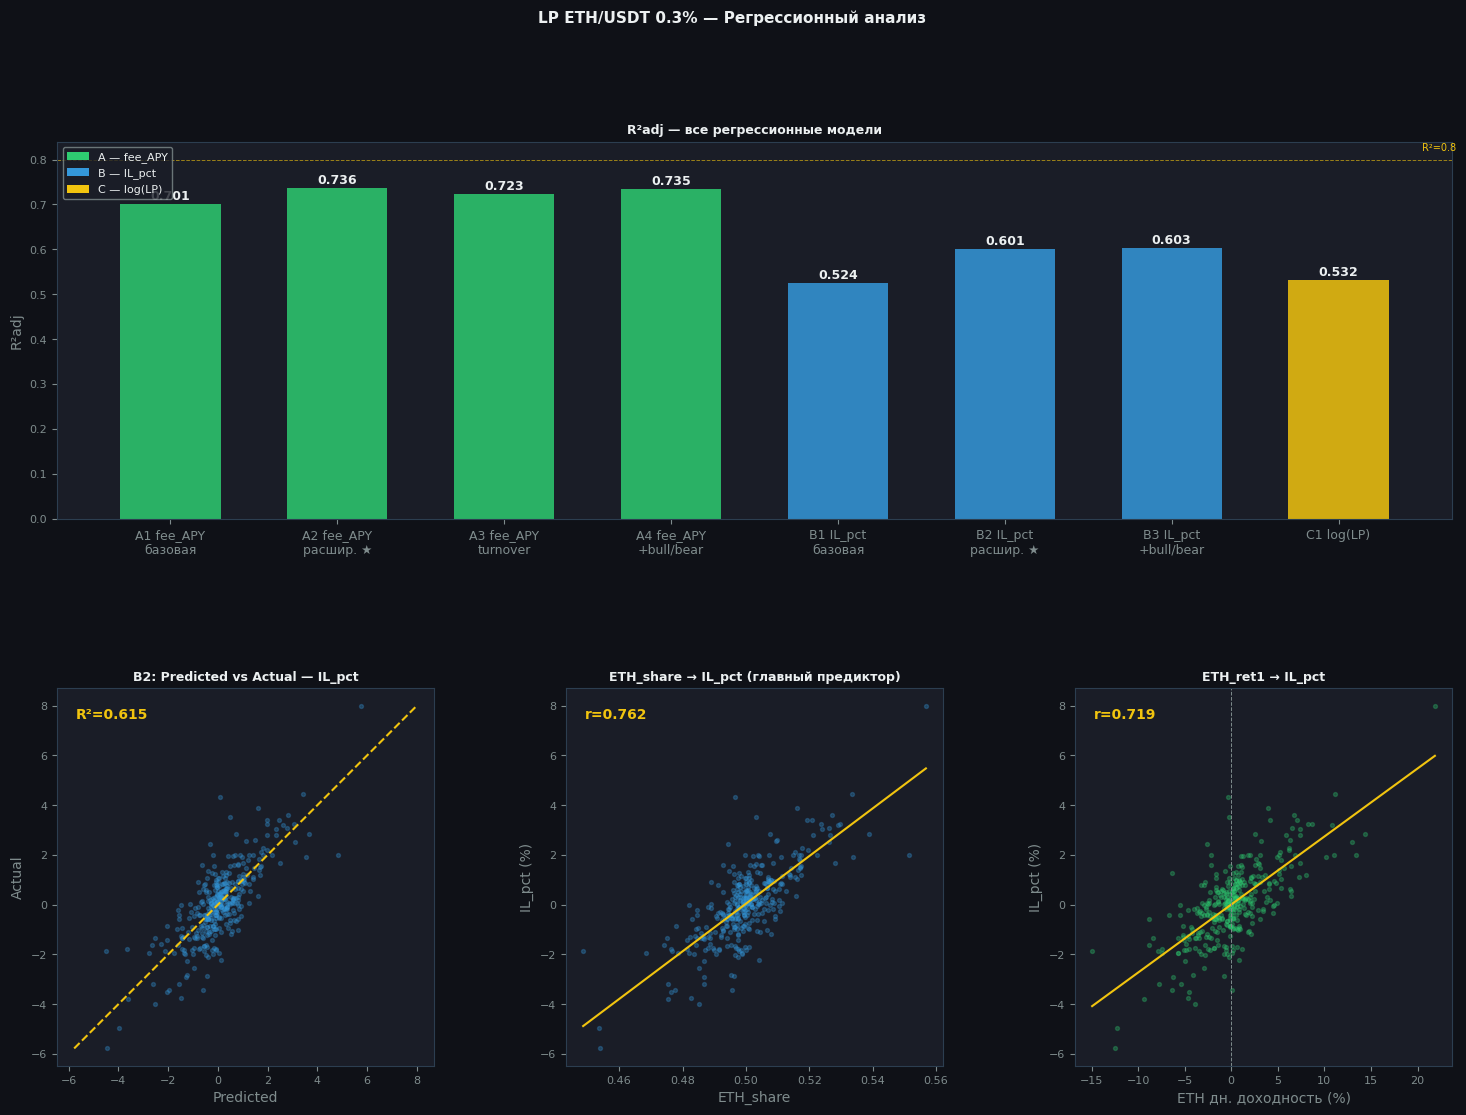

  ✅ usdt_eth_regression.png


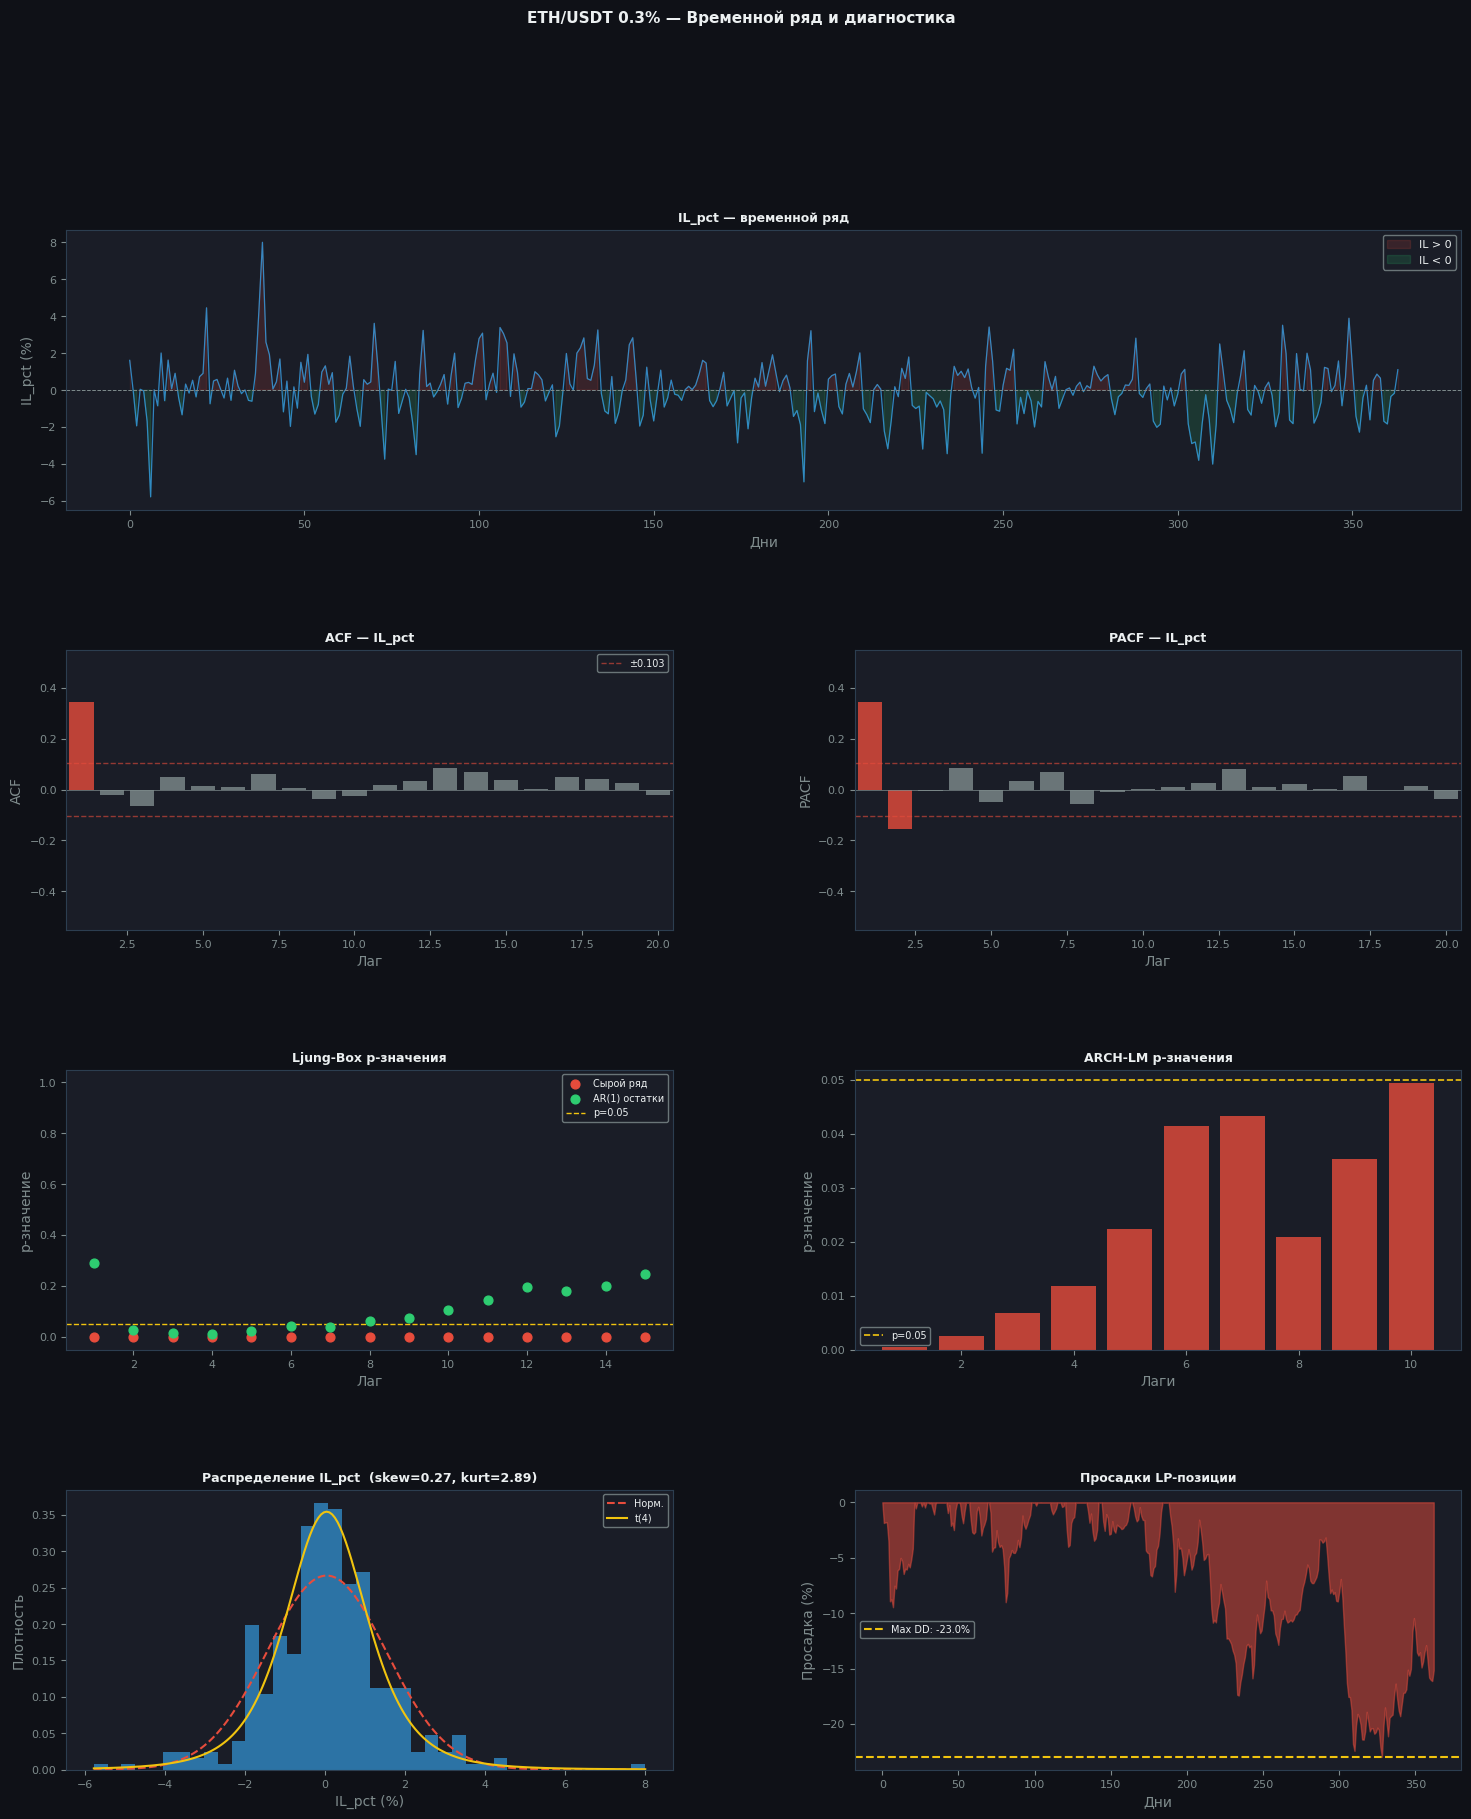

  ✅ usdt_eth_timeseries.png


In [15]:
print("Построение графиков...")

fig1 = plt.figure(figsize=(18,12))
fig1.patch.set_facecolor(DARK)
gs1 = gridspec.GridSpec(2, 3, figure=fig1, hspace=0.45, wspace=0.35)

ax0 = fig1.add_subplot(gs1[0, :])
ax_style(ax0, "R²adj — все регрессионные модели")
models_r2 = [
    ("A1 fee_APY\nбазовая",   rA1, GREEN),
    ("A2 fee_APY\nрасшир. ★", rA2, GREEN),
    ("A3 fee_APY\nturnover",   rA3, GREEN),
    ("A4 fee_APY\n+bull/bear", rA4, GREEN),
    ("B1 IL_pct\nбазовая",     rB1, BLUE),
    ("B2 IL_pct\nрасшир. ★",  rB2, BLUE),
    ("B3 IL_pct\n+bull/bear",  rB3, BLUE),
    ("C1 log(LP)",             rC1, GOLD),
]
lbs_ = [l for l,r,c in models_r2 if r]
r2s_ = [r["r2adj"] for l,r,c in models_r2 if r]
clrs_= [c for l,r,c in models_r2 if r]
bars = ax0.bar(range(len(lbs_)), r2s_, color=clrs_, alpha=0.85, width=0.6)
for bar,v in zip(bars, r2s_):
    ax0.text(bar.get_x()+bar.get_width()/2, v+0.01, f"{v:.3f}", ha="center", color=WHITE, fontsize=9, fontweight="bold")
ax0.set_xticks(range(len(lbs_))); ax0.set_xticklabels(lbs_, fontsize=9)
ax0.set_ylabel("R²adj", color=GRAY)
ax0.axhline(0.8, color=GOLD, ls="--", lw=0.7, alpha=0.6)
ax0.text(len(lbs_)-0.5, 0.82, "R²=0.8", color=GOLD, fontsize=7)
from matplotlib.patches import Patch
ax0.legend(handles=[Patch(fc=GREEN,label="A — fee_APY"), Patch(fc=BLUE,label="B — IL_pct"), Patch(fc=GOLD,label="C — log(LP)")],
           facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=8, loc="upper left")

ax1 = fig1.add_subplot(gs1[1, 0]); ax_style(ax1, "B2: Predicted vs Actual — IL_pct")
if rB2:
    s_b2 = df_m[XB2+["IL_pct"]].dropna().replace([np.inf,-np.inf],np.nan).dropna()
    ax1.scatter(rB2["yhat"], s_b2["IL_pct"].values, alpha=0.3, s=8, color=BLUE)
    mn = min(rB2["yhat"].min(), s_b2["IL_pct"].min()); mx = max(rB2["yhat"].max(), s_b2["IL_pct"].max())
    ax1.plot([mn,mx],[mn,mx], color=GOLD, lw=1.5, ls="--")
    ax1.set_xlabel("Predicted"); ax1.set_ylabel("Actual")
    ax1.text(0.05, 0.92, f"R²={rB2['r2']:.3f}", transform=ax1.transAxes, color=GOLD, fontsize=10, fontweight="bold")

ax2 = fig1.add_subplot(gs1[1, 1]); ax_style(ax2, "ETH_share → IL_pct (главный предиктор)")
sc = df_m[["ETH_share","IL_pct"]].dropna().replace([np.inf,-np.inf],np.nan).dropna()
ax2.scatter(sc["ETH_share"], sc["IL_pct"], alpha=0.3, s=8, color=BLUE)
z = np.polyfit(sc["ETH_share"], sc["IL_pct"], 1)
xr = np.linspace(sc["ETH_share"].min(), sc["ETH_share"].max(), 100)
ax2.plot(xr, np.polyval(z,xr), color=GOLD, lw=1.5)
r_sc = np.corrcoef(sc["ETH_share"], sc["IL_pct"])[0,1]
ax2.set_xlabel("ETH_share"); ax2.set_ylabel("IL_pct (%)")
ax2.text(0.05,0.92,f"r={r_sc:.3f}",transform=ax2.transAxes,color=GOLD,fontsize=10,fontweight="bold")

ax3 = fig1.add_subplot(gs1[1, 2]); ax_style(ax3, "ETH_ret1 → IL_pct")
sc2 = df_m[["ETH_ret1","IL_pct"]].dropna().replace([np.inf,-np.inf],np.nan).dropna()
ax3.scatter(sc2["ETH_ret1"]*100, sc2["IL_pct"], alpha=0.3, s=8, color=GREEN)
z2 = np.polyfit(sc2["ETH_ret1"], sc2["IL_pct"], 1)
xr2 = np.linspace(sc2["ETH_ret1"].min(), sc2["ETH_ret1"].max(), 100)
ax3.plot(xr2*100, np.polyval(z2,xr2), color=GOLD, lw=1.5)
r2c = np.corrcoef(sc2["ETH_ret1"], sc2["IL_pct"])[0,1]
ax3.set_xlabel("ETH дн. доходность (%)"); ax3.set_ylabel("IL_pct (%)")
ax3.text(0.05,0.92,f"r={r2c:.3f}",transform=ax3.transAxes,color=GOLD,fontsize=10,fontweight="bold")
ax3.axvline(0, color=GRAY, lw=0.7, ls="--")

fig1.suptitle("LP ETH/USDT 0.3% — Регрессионный анализ", color=WHITE, fontsize=11, fontweight="bold", y=0.99)
plt.savefig("usdt_eth_regression.png", dpi=150, bbox_inches="tight", facecolor=DARK, edgecolor="none")
plt.show(); print("  ✅ usdt_eth_regression.png")

fig2 = plt.figure(figsize=(18,20))
fig2.patch.set_facecolor(DARK)
gs2 = gridspec.GridSpec(4, 2, figure=fig2, hspace=0.5, wspace=0.3)

ax_ts = fig2.add_subplot(gs2[0, :]); ax_style(ax_ts, "IL_pct — временной ряд")
ax_ts.plot(range(len(y)), y, color=BLUE, lw=0.9, alpha=0.85)
ax_ts.axhline(0, color=GRAY, lw=0.7, ls="--")
ax_ts.fill_between(range(len(y)), y, 0, where=y>0, alpha=0.15, color=RED, label="IL > 0")
ax_ts.fill_between(range(len(y)), y, 0, where=y<0, alpha=0.15, color=GREEN, label="IL < 0")
ax_ts.set_xlabel("Дни"); ax_ts.set_ylabel("IL_pct (%)")
ax_ts.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=8)
if garch:
    ax_tb = ax_ts.twinx()
    ax_tb.plot(range(len(garch.conditional_volatility)), garch.conditional_volatility**2, color=GOLD, lw=0.8, alpha=0.6, ls="--", label="σ²ₜ GARCH")
    ax_tb.set_ylabel("Условная дисперсия", color=GOLD); ax_tb.tick_params(colors=GOLD)
    ax_tb.spines["right"].set_edgecolor("#2C3E50")

ax_acf = fig2.add_subplot(gs2[1, 0]); ax_style(ax_acf, "ACF — IL_pct")
lr2 = range(1,21); ap = [acv[k] for k in lr2]
ax_acf.bar(lr2, ap, color=[RED if abs(v)>ci else GRAY for v in ap], alpha=0.8)
ax_acf.axhline(ci, color=RED, ls="--", lw=1, alpha=0.6, label=f"±{ci:.3f}")
ax_acf.axhline(-ci, color=RED, ls="--", lw=1, alpha=0.6)
ax_acf.axhline(0, color=GRAY, lw=0.5); ax_acf.set_xlim(0.5,20.5); ax_acf.set_ylim(-0.55,0.55)
ax_acf.set_xlabel("Лаг"); ax_acf.set_ylabel("ACF")
ax_acf.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=7)

ax_pacf = fig2.add_subplot(gs2[1, 1]); ax_style(ax_pacf, "PACF — IL_pct")
pp = [pav[k] for k in lr2]
ax_pacf.bar(lr2, pp, color=[RED if abs(v)>ci else GRAY for v in pp], alpha=0.8)
ax_pacf.axhline(ci, color=RED, ls="--", lw=1, alpha=0.6)
ax_pacf.axhline(-ci, color=RED, ls="--", lw=1, alpha=0.6)
ax_pacf.axhline(0, color=GRAY, lw=0.5); ax_pacf.set_xlim(0.5,20.5); ax_pacf.set_ylim(-0.55,0.55)
ax_pacf.set_xlabel("Лаг"); ax_pacf.set_ylabel("PACF")

ax_lb = fig2.add_subplot(gs2[2, 0]); ax_style(ax_lb, "Ljung-Box p-значения")
llt = [r["lag"] for r in lb_r[:15]]
ax_lb.scatter(llt, [r["p"] for r in lb_r[:15]], color=RED, s=40, zorder=3, label="Сырой ряд")
ax_lb.scatter(llt, [r["p"] for r in lb_ar[:15]], color=GREEN, s=40, zorder=3, label=f"AR({rec_p}) остатки")
ax_lb.axhline(0.05, color=GOLD, lw=1, ls="--", label="p=0.05")
ax_lb.set_ylim(-0.05,1.05); ax_lb.set_xlabel("Лаг"); ax_lb.set_ylabel("p-значение")
ax_lb.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=7)

ax_ar = fig2.add_subplot(gs2[2, 1]); ax_style(ax_ar, "ARCH-LM p-значения")
pva = [r["p"] for r in arch_r]
ax_ar.bar([r["lag"] for r in arch_r], pva, color=[RED if p<0.05 else GREEN for p in pva], alpha=0.8)
ax_ar.axhline(0.05, color=GOLD, lw=1.2, ls="--", label="p=0.05")
ax_ar.set_xlabel("Лаги"); ax_ar.set_ylabel("p-значение")
ax_ar.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=7)

ax_h = fig2.add_subplot(gs2[3, 0]); ax_style(ax_h, f"Распределение IL_pct  (skew={jb_skew:.2f}, kurt={jb_kurt:.2f})")
ax_h.hist(y, bins=40, color=BLUE, alpha=0.7, density=True, edgecolor="none")
xr = np.linspace(y.min(), y.max(), 200)
ax_h.plot(xr, st.norm.pdf(xr, y.mean(), y.std()), color=RED, lw=1.5, ls="--", label="Норм.")
tdf = max(4, int(6/max(jb_kurt, 0.1)))
ax_h.plot(xr, st.t.pdf(xr, tdf, y.mean(), y.std()*np.sqrt((tdf-2)/tdf)), color=GOLD, lw=1.5, label=f"t({tdf})")
ax_h.set_xlabel("IL_pct (%)"); ax_h.set_ylabel("Плотность")
ax_h.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=7)

ax_dd = fig2.add_subplot(gs2[3, 1]); ax_style(ax_dd, "Просадки LP-позиции")
cu_ = np.cumprod(1+lp_ret); dd_ = (cu_ - np.maximum.accumulate(cu_)) / np.maximum.accumulate(cu_)
ax_dd.fill_between(range(len(dd_)), dd_*100, 0, color=RED, alpha=0.5)
ax_dd.axhline(mdd_lp*100, color=GOLD, ls="--", lw=1.5, label=f"Max DD: {mdd_lp*100:.1f}%")
ax_dd.set_xlabel("Дни"); ax_dd.set_ylabel("Просадка (%)")
ax_dd.legend(facecolor=PANEL, edgecolor=GRAY, labelcolor=WHITE, fontsize=7)

fig2.suptitle("ETH/USDT 0.3% — Временной ряд и диагностика", color=WHITE, fontsize=11, fontweight="bold", y=0.99)
plt.savefig("usdt_eth_timeseries.png", dpi=150, bbox_inches="tight", facecolor=DARK, edgecolor="none")
plt.show(); print("  ✅ usdt_eth_timeseries.png")

## 8. Финальная сводка

In [16]:
print(SEP)
print("  ФИНАЛЬНАЯ СВОДКА — LP ETH/USDT 0.3%")
print(SEP)
print(f"  Пул    : 0x4e68Ccd3E89f51C3074ca5072bbAC773960dFa36")
print(f"  Период : {df['day'].min().date()} → {df['day'].max().date()}")
print(f"  N      : {len(df_m)} наблюдений")

print(f"\n  РЕГРЕССИЯ:")
if rA2: print(f"  fee_APY (A2) : R²={rA2['r2']:.4f}  R²adj={rA2['r2adj']:.4f}  F={rA2['f']:.1f}  N={rA2['n']}")
if rB2: print(f"  IL_pct  (B2) : R²={rB2['r2']:.4f}  R²adj={rB2['r2adj']:.4f}  F={rB2['f']:.1f}  N={rB2['n']}")
if rC1: print(f"  log(LP) (C1) : R²={rC1['r2']:.4f}  R²adj={rC1['r2adj']:.4f}  F={rC1['f']:.1f}  N={rC1['n']}")

print(f"\n  ВРЕМЕННОЙ РЯД IL_pct:")
print(f"  ADF   : stat={adf['stat']:.3f}  p={adf['p']:.4f}  → {'стационарен' if adf_ok else 'нестационарен'}")
print(f"  JB    : stat={jbs:.1f}  p={jbp:.4f}  → {'нормальное' if jb_ok else 'не нормальное'}")
print(f"  ARCH  : LM(1)={arch_r[0]['LM']:.2f}  p={arch_r[0]['p']:.4f}  → {'есть ARCH-эффекты' if arch_d else 'нет'}")
print(f"  ARMA  : AIC→{bao}  BIC→{bbo}  → рекомендуем ARMA({rec_p_a},{rec_q})")
if garch:
    print(f"  GARCH : α={garch.params['alpha[1]']:.4f}  β={garch.params['beta[1]']:.4f}  α+β={garch.params['alpha[1]']+garch.params['beta[1]']:.4f}")
print(f"  Спецификация: AR({rec_p})–GARCH(1,1)")

print(f"\n  РИСК:")
print(f"  VaR (95%, 1 день) : {v95*100:.2f}%  (${v95*20000:.1f})")
print(f"  CVaR (95%, 1 день): {cv95*100:.2f}%  (${cv95*20000:.1f})")
print(f"  Sharpe (год.)     : {sharpe_r(lp_ret)*252**.5:.4f}")
print(f"  Sortino (год.)    : {sortino_r(lp_ret)*252**.5:.4f}")
print(f"  Calmar Ratio      : {cal_lp:.4f}")
print(f"  Max Drawdown      : {mdd_lp*100:.2f}%")
print(f"  Годовая дох. LP   : {ann_lp*100:.2f}%")
print(f"  Годовая дох. HODL : {ann_hd*100:.2f}%")
print(f"  Win Rate LP       : {np.mean(lp_ret>0)*100:.2f}%")
print(f"  Дельта (ср.)      : {np.nanmean(delta):.4f}")

print(f"\n  ФАЙЛЫ:")
print(f"  usdt_eth_regression.png  — регрессионный обзор")
print(f"  usdt_eth_timeseries.png  — временной ряд IL_pct и диагностика")
print(SEP)
print("  ✅ АНАЛИЗ ЗАВЕРШЁН")
print(SEP)

  ФИНАЛЬНАЯ СВОДКА — LP ETH/USDT 0.3%
  Пул    : 0x4e68Ccd3E89f51C3074ca5072bbAC773960dFa36
  Период : 2025-03-31 → 2026-03-30
  N      : 364 наблюдений

  РЕГРЕССИЯ:
  fee_APY (A2) : R²=0.7449  R²adj=0.7361  F=84.2  N=359
  IL_pct  (B2) : R²=0.6149  R²adj=0.6015  F=45.9  N=358
  log(LP) (C1) : R²=0.5492  R²adj=0.5322  F=32.2  N=358

  ВРЕМЕННОЙ РЯД IL_pct:
  ADF   : stat=-4.501  p=0.0010  → стационарен
  JB    : stat=130.9  p=0.0000  → не нормальное
  ARCH  : LM(1)=12.02  p=0.0005  → есть ARCH-эффекты
  ARMA  : AIC→(5, 5)  BIC→(0, 5)  → рекомендуем ARMA(0,1)
  Спецификация: AR(1)–GARCH(1,1)

  РИСК:
  VaR (95%, 1 день) : 1.93%  ($386.0)
  CVaR (95%, 1 день): 3.11%  ($621.4)
  Sharpe (год.)     : 1.8261
  Sortino (год.)    : 2.8487
  Calmar Ratio      : 2.1789
  Max Drawdown      : -22.96%
  Годовая дох. LP   : 50.04%
  Годовая дох. HODL : 3.42%
  Win Rate LP       : 56.75%
  Дельта (ср.)      : 0.5000

  ФАЙЛЫ:
  usdt_eth_regression.png  — регрессионный обзор
  usdt_eth_timeseries.png